# Exploratory Data Analysis (EDA): Medical Insurance Cost Prediction

## 1. Project Overview & Problem Statement
The objective of this exploratory data analysis (EDA) is to understand individual health insurance billing data and identify which demographic and health indicators have the greatest influence on medical costs.

This exploratory study serves as the foundational data preparation phase before training predictive machine learning models (e.g., Linear Regression, Ridge, Random Forest, and Gradient Boosting Regressors) to predict medical charges for insurance beneficiaries.

### Dataset Details
- **Dataset Name:** Medical Cost Personal Datasets
- **Source:** [Kaggle - Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance)
- **Records:** 1,338 individual cases
- **Features:**
  - `age`: Age of primary beneficiary (years)
  - `sex`: Gender of the beneficiary (`male`, `female`)
  - `bmi`: Body Mass Index ($kg / m^2$)
  - `children`: Number of children/dependents covered by health insurance
  - `smoker`: Smoking status (`yes`, `no`)
  - `region`: US residential geographic region (`northeast`, `southeast`, `southwest`, `northwest`)
  - `charges`: Individual medical costs billed by health insurance (Continuous numerical target in USD)


## 2. Importing Libraries and Loading Data
We begin by importing standard Python data analysis and visualization packages (`pandas`, `numpy`, `matplotlib`, `seaborn`) and reading `insurance.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

# Load the dataset
df = pd.read_csv('insurance.csv')

# View the first 5 records
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Dataset Inspection & Structure
Let's inspect the dimensions, column data types, and non-null values to understand the table schema.

In [2]:
print(f"Total Observations (Rows): {df.shape[0]}")
print(f"Total Features (Columns):  {df.shape[1]}\n")
df.info()

Total Observations (Rows): 1338
Total Features (Columns):  7

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


## 4. Data Cleaning & Sanity Checks
We inspect the data for:
1. Missing / null values
2. Duplicate rows
3. Statistical summaries across both numerical and categorical features

In [3]:
# Check for missing / null values
print("--- Missing Values Count ---")
print(df.isnull().sum())

# Check for duplicate rows
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicate_count}")

if duplicate_count > 0:
    print("\nDuplicate row preview:")
    print(df[df.duplicated(keep=False)])
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"\nShape after dropping duplicates: {df.shape}")

--- Missing Values Count ---
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows found: 1

Duplicate row preview:
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631

Shape after dropping duplicates: (1337, 7)


In [4]:
# Numerical summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.222139,14.044333,18.0000,27.000,39.0000,51.00000,64.00000
bmi,1337.0,30.663452,6.100468,15.9600,26.290,30.4000,34.70000,53.13000
children,1337.0,1.095737,1.205571,0.0000,0.000,1.0000,2.00000,5.00000
charges,1337.0,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801


In [5]:
# Categorical summary statistics
df.describe(include=['object']).T

,count,unique,top,freq
sex,1337,2,male,675
smoker,1337,2,no,1063
region,1337,4,southeast,364


### Summary Observations:
- **Age:** Beneficiaries range from 18 to 64 years old, with an average age of ~39.2 years.
- **BMI:** Mean is ~30.66 $kg/m^2$ (placing the sample average just above the clinical obesity threshold of 30), ranging from 15.96 to 53.13.
- **Children:** 50% of the individuals have 0 or 1 covered children; maximum is 5.
- **Charges (Target):** Wide variance from $1,121.87 to $63,770.43, with a median of $9,382.03 and mean of $13,270.42, indicating a distinct right skew.
- **Categorical:** Gender and region distributions are well-balanced; non-smokers make up ~79.5% of policyholders.

## 5. Target Variable Analysis (`charges`)
Let's explore the distribution of medical charges using both a histogram with KDE and a boxplot to evaluate skewness and extreme values.

Skewness of charges: 1.52


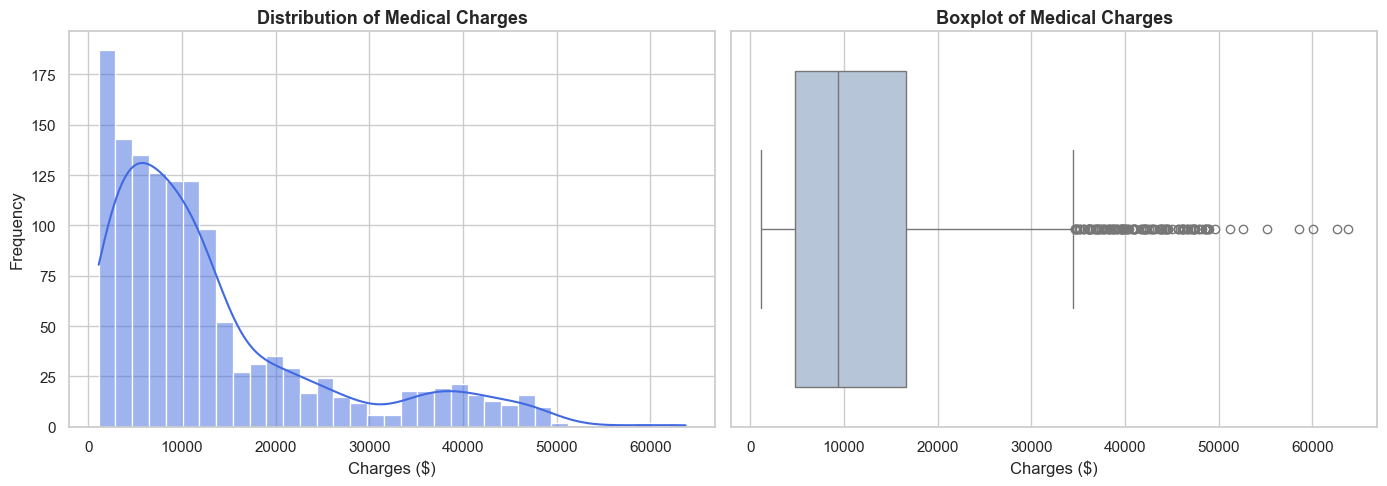

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(df['charges'], kde=True, ax=axes[0], color='royalblue', bins=35)
axes[0].set_title('Distribution of Medical Charges', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Charges ($)')
axes[0].set_ylabel('Frequency')

# Boxplot
sns.boxplot(x=df['charges'], ax=axes[1], color='lightsteelblue')
axes[1].set_title('Boxplot of Medical Charges', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Charges ($)')

plt.tight_layout()
plt.show()

print(f"Skewness of charges: {df['charges'].skew():.2f}")

The target variable `charges` is positively skewed (skewness = 1.51) with a long right tail of higher expenses. In machine learning model training, a log transformation (`np.log1p(charges)`) will often benefit linear models by stabilizing variance and normalizing residuals.

## 6. Univariate Analysis of Independent Features
We examine the individual distributions of continuous numerical features (`age`, `bmi`) and categorical variables (`sex`, `smoker`, `region`, `children`).

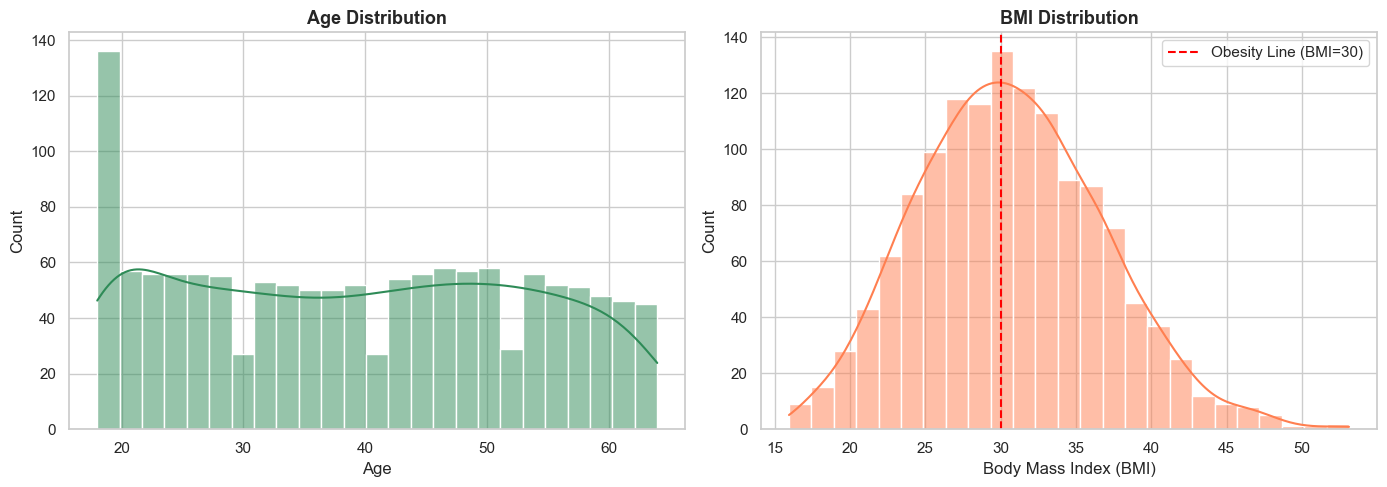

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age distribution
sns.histplot(df['age'], kde=True, bins=25, ax=axes[0], color='seagreen')
axes[0].set_title('Age Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

# BMI distribution
sns.histplot(df['bmi'], kde=True, bins=25, ax=axes[1], color='coral')
axes[1].axvline(30, color='red', linestyle='--', label='Obesity Line (BMI=30)')
axes[1].set_title('BMI Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Body Mass Index (BMI)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

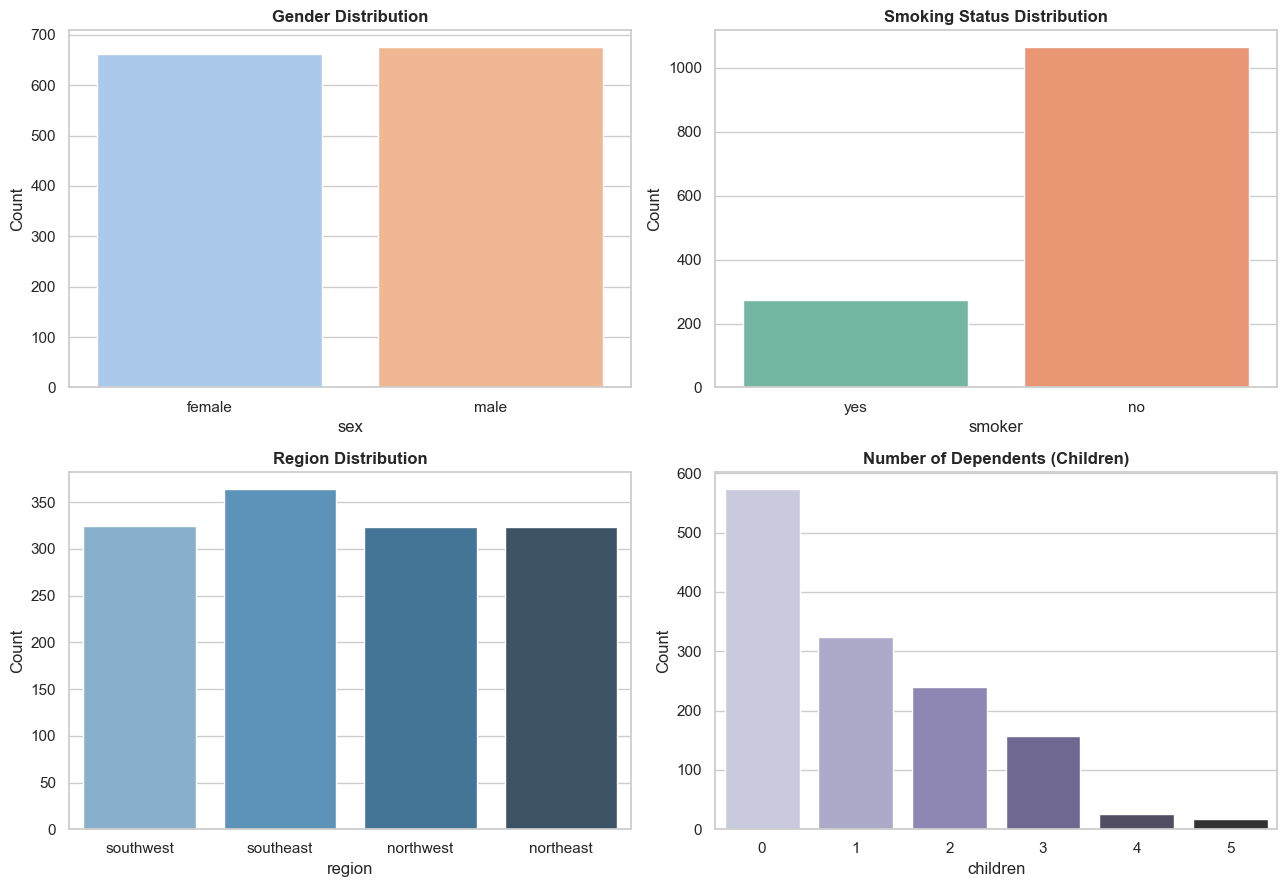

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Gender
sns.countplot(data=df, x='sex', hue='sex', legend=False, ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('Gender Distribution', fontweight='bold')
axes[0, 0].set_ylabel('Count')

# Smoker
sns.countplot(data=df, x='smoker', hue='smoker', legend=False, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Smoking Status Distribution', fontweight='bold')
axes[0, 1].set_ylabel('Count')

# Region
sns.countplot(data=df, x='region', hue='region', legend=False, ax=axes[1, 0], palette='Blues_d')
axes[1, 0].set_title('Region Distribution', fontweight='bold')
axes[1, 0].set_ylabel('Count')

# Children
sns.countplot(data=df, x='children', hue='children', legend=False, ax=axes[1, 1], palette='Purples_d')
axes[1, 1].set_title('Number of Dependents (Children)', fontweight='bold')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 7. Bivariate & Multivariate Analysis (Relationships with Charges)
We analyze how medical charges vary with respect to lifestyle factors and demographic characteristics.

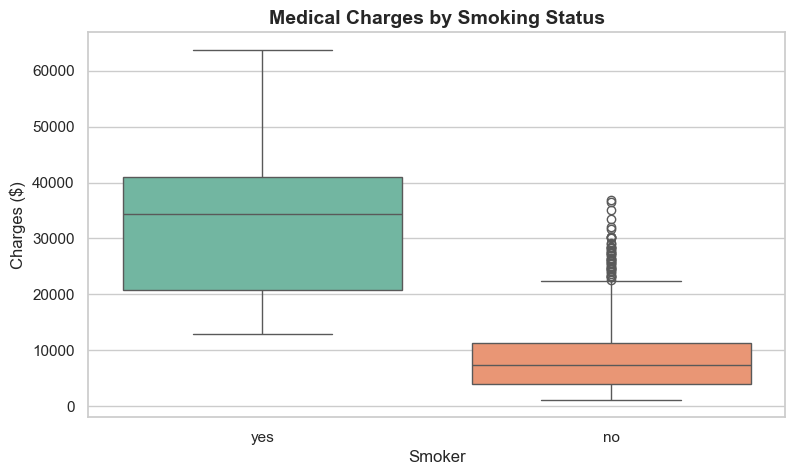

,count,mean,median,std
smoker,,,,
no,1063,8440.660307,7345.72660,5992.973800
yes,274,32050.231832,34456.34845,11541.547176


In [9]:
# Charges by Smoking Status
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='smoker', y='charges', hue='smoker', legend=False, palette=['#66c2a5', '#fc8d62'])
plt.title('Medical Charges by Smoking Status', fontsize=14, fontweight='bold')
plt.xlabel('Smoker')
plt.ylabel('Charges ($)')
plt.show()

# Statistical aggregation
df.groupby('smoker')['charges'].agg(['count', 'mean', 'median', 'std'])

Smoking has the single largest impact on medical charges in the dataset: smokers have an average cost of **$32,050**, compared to **$8,440** for non-smokers (nearly a 4x increase).

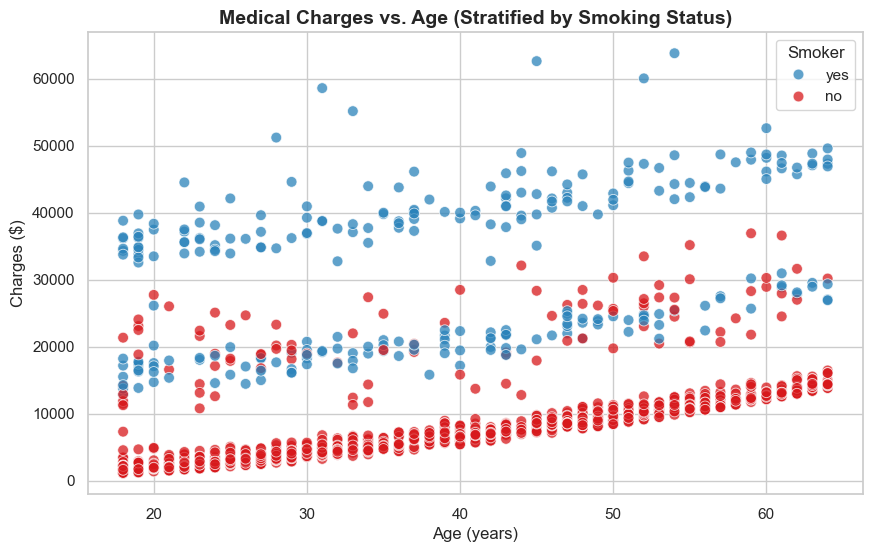

In [10]:
# Charges vs Age by Smoking Status
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', palette=['#2b83ba', '#d7191c'], alpha=0.75, s=60)
plt.title('Medical Charges vs. Age (Stratified by Smoking Status)', fontsize=14, fontweight='bold')
plt.xlabel('Age (years)')
plt.ylabel('Charges ($)')
plt.legend(title='Smoker')
plt.show()

Medical charges exhibit a consistent positive trajectory with age across all groups. Distinct bands emerge:
1. Lower tier: Non-smokers with standard charges.
2. Middle tier: Higher-risk non-smokers or non-obese smokers.
3. Top tier: Smokers with elevated BMI.

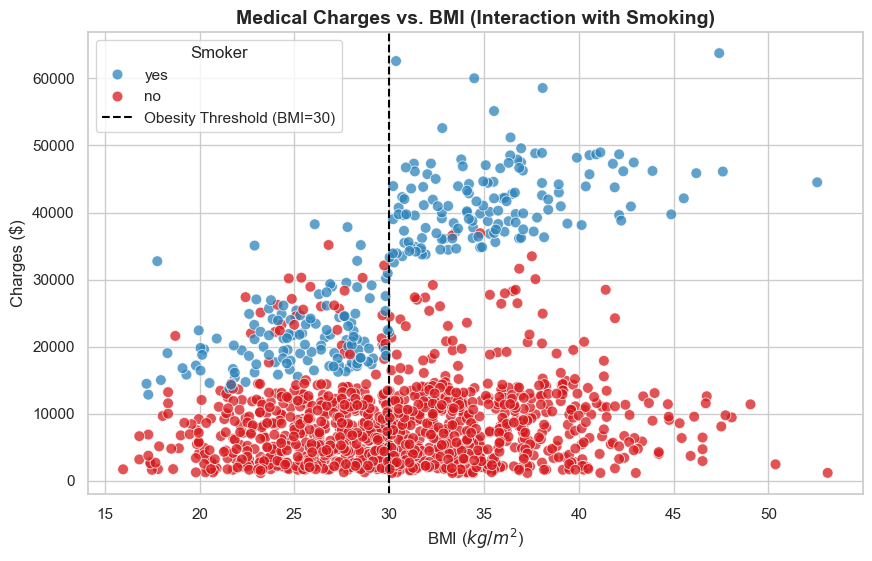

In [11]:
# Charges vs BMI by Smoking Status
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', palette=['#2b83ba', '#d7191c'], alpha=0.75, s=60)
plt.axvline(30, color='black', linestyle='--', label='Obesity Threshold (BMI=30)')
plt.title('Medical Charges vs. BMI (Interaction with Smoking)', fontsize=14, fontweight='bold')
plt.xlabel('BMI ($kg/m^2$)')
plt.ylabel('Charges ($)')
plt.legend(title='Smoker')
plt.show()

A clear interaction effect between BMI and Smoking is visible:
- For **non-smokers**, charges remain low even at high BMI values.
- For **smokers with BMI > 30**, charges surge past $35,000 to $40,000+.

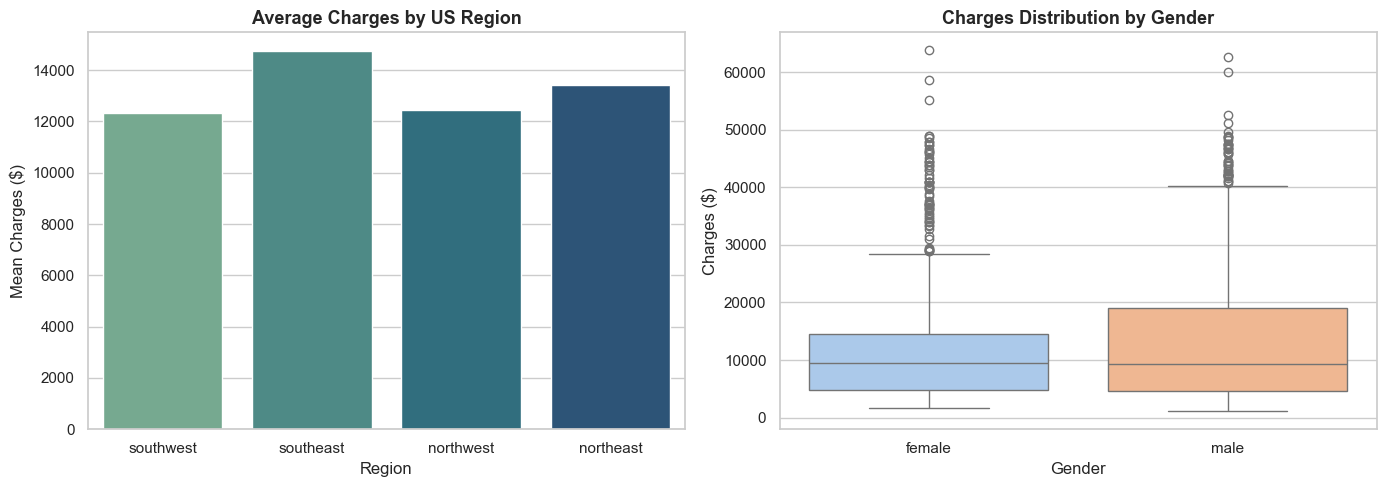

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Charges by Region
sns.barplot(data=df, x='region', y='charges', hue='region', legend=False, ax=axes[0], estimator='mean', errorbar=None, palette='crest')
axes[0].set_title('Average Charges by US Region', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Mean Charges ($)')
axes[0].set_xlabel('Region')

# Charges by Sex
sns.boxplot(data=df, x='sex', y='charges', hue='sex', legend=False, ax=axes[1], palette='pastel')
axes[1].set_title('Charges Distribution by Gender', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Charges ($)')
axes[1].set_xlabel('Gender')

plt.tight_layout()
plt.show()

## 8. Correlation Analysis
We calculate the Pearson correlation matrix for the continuous numerical variables.

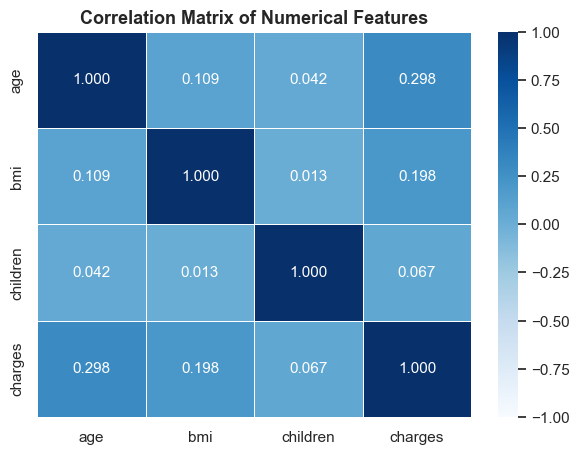

In [13]:
num_cols = ['age', 'bmi', 'children', 'charges']
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features', fontsize=13, fontweight='bold')
plt.show()

## 9. Key Findings & Insights
1. **Smoking is the strongest determinant:** Smokers face mean medical costs roughly 4 times that of non-smokers (~$32,050 vs ~$8,440).
2. **BMI × Smoking interaction:** Obesity combined with smoking triggers the highest insurance charges in the dataset (frequently over $35,000–$40,000).
3. **Age has a steady positive effect:** Medical charges trend upwards with age ($r = 0.299$).
4. **Target Skewness:** The distribution of `charges` is moderately right-skewed; applying a logarithmic transformation will benefit regression models.
5. **Minor Impact Variables:** Gender and geographic region demonstrate minimal direct influence on total medical bills.

## 10. Data Preparation for Model Training & Testing
Based on our EDA findings, we perform the exact data preprocessing needed before model training:
1. **Feature Encoding:**
   - Binary encoding for `sex` (`female`: 0, `male`: 1) and `smoker` (`no`: 0, `yes`: 1).
   - One-Hot Encoding for `region` (`drop_first=True` to avoid the dummy variable trap).
2. **Train-Test Split:**
   - Splitting features ($X$) and target ($y$) into 80% training and 20% testing sets using `train_test_split`.

In [14]:
# 1. Feature Encoding
df_prep = df.copy()
df_prep['sex'] = df_prep['sex'].map({'female': 0, 'male': 1})
df_prep['smoker'] = df_prep['smoker'].map({'no': 0, 'yes': 1})
df_prep = pd.get_dummies(df_prep, columns=['region'], drop_first=True, dtype=int)

# Preview preprocessed dataset
df_prep.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


In [15]:
# 2. Separate Features (X) and Target (y)
X = df_prep.drop(columns=['charges'])
y = df_prep['charges']

# 3. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training feature set shape: {X_train.shape}")
print(f"Testing feature set shape:  {X_test.shape}")
print(f"Training target shape:      {y_train.shape}")
print(f"Testing target shape:       {y_test.shape}")
print("\nDataset is prepared and ready for model training and evaluation!")

Training feature set shape: (1069, 8)
Testing feature set shape:  (268, 8)
Training target shape:      (1069,)
Testing target shape:       (268,)

Dataset is prepared and ready for model training and evaluation!
